# 01 – Data audit

**Purpose:** check whether the Monash sensor data can be trusted before any model is built, and record every problem found and how it was handled (report Section 2.4).

This notebook reads the small processed files in `data/processed/`. To rebuild those from the raw 2 GB files, place them in `data/raw/` and run `python -m occupancy.pipeline` (see README).

**Structure:** (1) occupancy data – size, duplicates, coverage, daily patterns, unusual events; (2) environmental data – frozen sensors; (3) summary of decisions.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # make the occupancy package importable

import pandas as pd
from occupancy import clean, plots
from occupancy.config import PROCESSED_DIR, FIGURES_DIR, SPACE_ORDER

hourly = clean.load_hourly(PROCESSED_DIR / "occupancy_hourly.csv")
print(f"{len(hourly):,} space-hours, {hourly['hour'].min():%d %b %Y} to {hourly['hour'].max():%d %b %Y}")

60,988 space-hours, 24 Nov 2023 to 22 Apr 2026


## 1. Occupancy data

### 1.1 Size and duplicates
The raw file holds 9,091,732 events. `clean.build_hourly_occupancy` removed **4 exact duplicate events** and aggregated the rest into one row per space per hour. No headcounts were missing or negative.

In [2]:
summary = hourly.groupby("space").agg(
    hours_with_data=("n_readings", "size"),
    readings=("n_readings", "sum"),
    first=("hour", "min"), last=("hour", "max"),
    max_headcount=("max_headcount", "max"),
).reindex(SPACE_ORDER)
summary["first"] = summary["first"].dt.strftime("%d %b %Y"); summary["last"] = summary["last"].dt.strftime("%d %b %Y")
summary

,hours_with_data,readings,first,last,max_headcount
space,,,,,
G.20 Breakout,10350,1894870,03 Mar 2024,22 Apr 2026,72
G.25 MSM Lab,15892,1500393,03 Mar 2024,22 Apr 2026,38
Space A,14948,2169461,24 Nov 2023,22 Apr 2026,40
Space B,15236,1975422,24 Nov 2023,22 Apr 2026,15
Space C,4562,1551582,01 May 2024,30 Dec 2024,36


### 1.2 Coverage (Figure 2)
Hours with no readings are **missing**, not zero people. Space C only has data May–Dec 2024, so it cannot be used in a 2025 test period.

space
G.20 Breakout    88%
G.25 MSM Lab     89%
Space A          98%
Space B          98%
Space C          28%


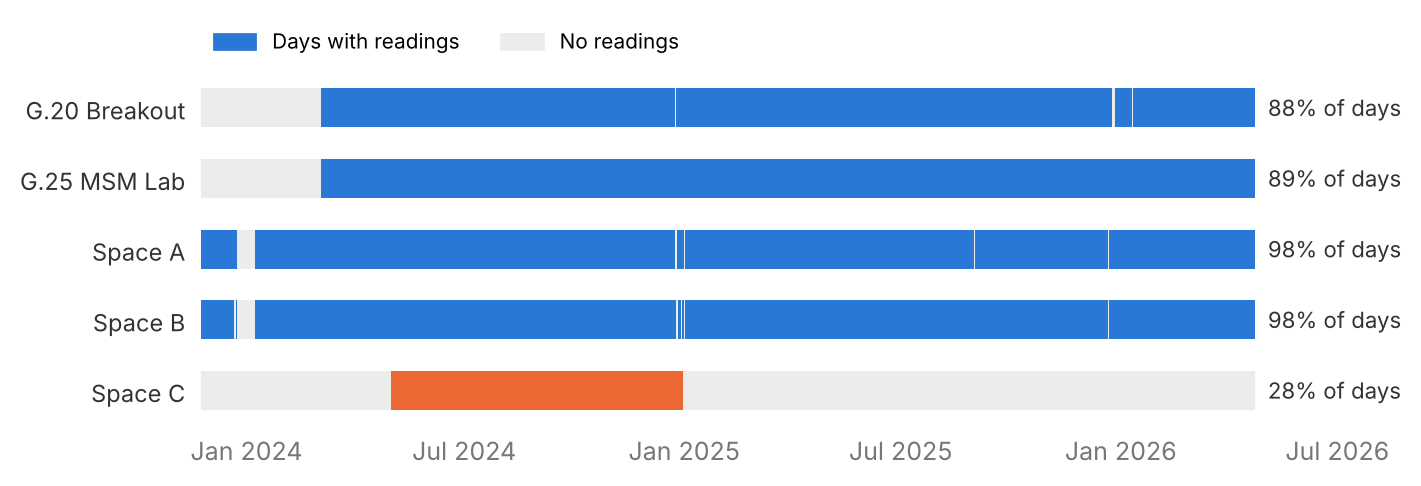

In [3]:
coverage = clean.daily_coverage(hourly)
print((coverage > 0).mean().reindex(SPACE_ORDER).map("{:.0%}".format).to_string())
fig = plots.coverage_timeline(coverage)
fig.savefig(FIGURES_DIR / "fig2_occupancy_coverage.png", facecolor="white")

### 1.3 Daily and weekly patterns (Figure 1)
Clear, repeatable cycles (low overnight, peak early afternoon, weekdays busier than weekends) suggest occupancy is forecastable from time and calendar inputs.

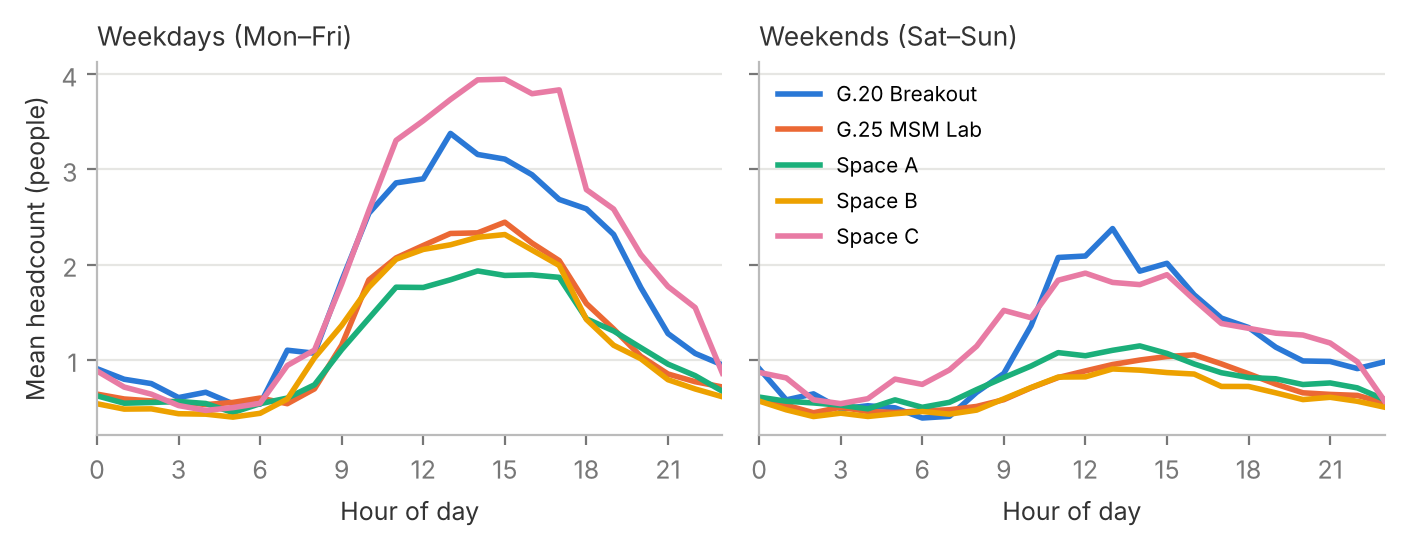

In [4]:
fig = plots.occupancy_profiles(hourly)
fig.savefig(FIGURES_DIR / "fig1_occupancy_profiles.png", facecolor="white")

### 1.4 Night-time readings
Mean headcount overnight is around 0.5 rather than 0. Possible causes: cleaners, security, or false detections. This is noted as a limitation (the sensor is not perfect ground truth).

In [5]:
night = hourly[hourly["hour_of_day"].between(1, 4)]
night.groupby("space")["mean_headcount"].mean().reindex(SPACE_ORDER).round(2)

space
G.20 Breakout    0.67
G.25 MSM Lab     0.54
Space A          0.54
Space B          0.45
Space C          0.61
Name: mean_headcount, dtype: float64

### 1.5 Unusual events
Hours with a peak of 30+ people are flagged (`is_event`) but **kept**. The maximum, 72 people in G.20 at 11:20 am on Sunday 4 Aug 2024, coincides with Monash Clayton Open Day: a genuine event, not a sensor fault.

In [6]:
print(f"{hourly['is_event'].sum()} flagged hours of {len(hourly):,} ({hourly['is_event'].mean():.2%})")
hourly.nlargest(5, "max_headcount")[["hour", "space", "mean_headcount", "max_headcount"]]

82 flagged hours of 60,988 (0.13%)


,hour,space,mean_headcount,max_headcount
2106,2024-08-04 11:00:00+10:00,G.20 Breakout,40.167,72
9531,2026-02-19 19:00:00+11:00,G.20 Breakout,49.322,66
2107,2024-08-04 12:00:00+10:00,G.20 Breakout,36.710,61
2108,2024-08-04 13:00:00+10:00,G.20 Breakout,31.566,61
9532,2026-02-19 20:00:00+11:00,G.20 Breakout,28.962,58


## 2. Environmental data – frozen sensors (Figure 3)
Each record has the sensor's own measurement time (inside `jsondata`) and the database arrival time (`createdate`). A sensor is **frozen** in a month when records arrive but its own clock shows at most one distinct time.

In [7]:
health = pd.read_csv(PROCESSED_DIR / "env_sensor_health_monthly.csv")
health.pivot_table(index="period", columns="sensorid", values="status", aggfunc="first").fillna("–")

sensorid,6012002000227,6012002000241,6012002000326,6012002000777,6012002000869
period,,,,,
2024-02,–,frozen,frozen,frozen,working
2024-03,–,frozen,frozen,frozen,working
2024-04,–,frozen,frozen,frozen,working
2024-05,frozen,frozen,frozen,frozen,working
2024-06,frozen,frozen,frozen,–,working
2024-07,frozen,frozen,frozen,–,frozen
2024-08,frozen,frozen,frozen,–,frozen
2024-09,frozen,frozen,frozen,–,frozen
2024-10,frozen,frozen,frozen,–,frozen


In [8]:
pd.read_csv(PROCESSED_DIR / "env_sensor_valid_periods.csv")

,sensorid,records,distinct_times,valid_from,valid_to
0,6012002000227,21363,1,NaN,NaN
1,6012002000241,58908,2,NaN,NaN
2,6012002000326,58909,29039,2025-09-07 20:09:30+10:00,2026-04-22 23:12:41+10:00
3,6012002000777,10926,1,NaN,NaN
4,6012002000869,29341,13800,2024-02-29 17:04:56+11:00,2024-06-14 03:35:44+10:00


Every sensor froze at some point. Only …869 (G.38, 29 Feb – 14 Jun 2024) and …326 (unmapped, 7 Sep 2025 – 22 Apr 2026) produced valid readings, and neither can be placed in a room with an occupancy sensor. Example: sensor …227 repeats 666 ppm measured on 11 Dec 2023 for five months.

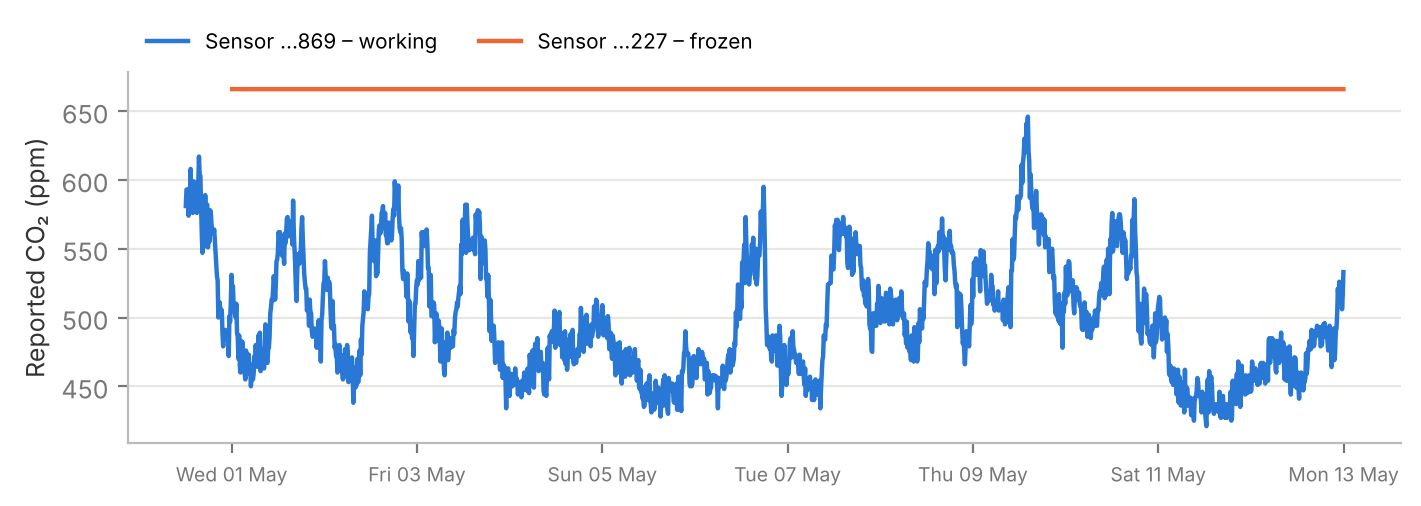

In [9]:
ext = pd.read_csv(PROCESSED_DIR / "env_fig3_extract.csv", dtype={"sensorid": str})
for col in ["arrived_at", "measured_at"]:
    ext[col] = pd.to_datetime(ext[col], utc=True).dt.tz_convert("Australia/Melbourne")
fig = plots.frozen_vs_working(ext, "6012002000869", "6012002000227", "2024-04-30 12:00", "2024-05-13 00:00")
fig.savefig(FIGURES_DIR / "fig3_frozen_sensor.png", facecolor="white")

## 3. Decisions carried forward

| Issue | Decision |
|---|---|
| 4 duplicate events | Removed |
| Daylight-saving changes | Timestamps rounded in UTC, then converted to local time (tested) |
| Hours with no readings | Treated as missing, not zero |
| Space C has no data after Dec 2024 | Excluded from the 2025 test |
| Open Day and other 30+ peaks | Kept and flagged (`is_event`) |
| Night-time ~0.5 headcount | Kept; reported as a limitation |
| All environmental sensors frozen at some point; none co-located with occupancy | Environmental data excluded from modelling |